# FIT5215 / FIT3181 Assignment 1 - Kaggle Starter Notebook

This notebook provides a complete, deliberately simple workflow: download the training data, load the hidden-label Kaggle test set, create a validation split, train a starter CNN, and write a valid Kaggle submission.

The starter notebook is intended to run in **Google Colab with a GPU runtime**. Improve the data augmentation, model architecture, optimization, and validation procedure for your own submission.

## Before you start

1. In Colab, select **Runtime → Change runtime type → GPU**.
2. Make your own copy of this notebook.
3. On the competition **Data** tab, download `test_set.zip` and upload it to the Colab Files pane. When extracted, it creates a `test_set` folder containing the `test_dataset` image folder and the sample submission template `my_solution.csv`.

   **If your computer automatically decompresses the file downloaded from Kaggle, compress the complete extracted `test_set` folder again, name the new archive `test_set.zip`, and upload that ZIP file to Colab.**

4. The labelled training set is downloaded separately from Google Drive. Use the [primary training archive](https://drive.google.com/file/d/10Y65ykpja1t6UWt3imPPbZkqhe0kOPL9/view?usp=sharing), or manually switch to the [backup training archive](https://drive.google.com/file/d/1uc7uQ5myz7k74ZO460Q04B35_GekQeGi/view?usp=sharing) if the primary link is unavailable.

The release contains **9,466 labelled training images across 20 classes** and **11,681 unlabelled 64×64 test images**. The submission template contains the columns `ID,Label`. Use only the provided training labels and follow the assignment and competition rules.

In [1]:
%pip install -q -U "transformers==5.3.0" "huggingface_hub>=1.23,<2" accelerate safetensors tqdm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.4/57.4 kB 5.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.7/10.7 MB 147.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 842.9/842.9 kB 60.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 394.3/394.3 kB 35.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.2/80.2 kB 8.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 118.8 MB/s eta 0:00:00


In [2]:
from __future__ import annotations

import copy
import os
import random
import zipfile
from pathlib import Path
import gc
import shutil
import time

from tqdm.auto import tqdm
from transformers import SiglipVisionModel

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from IPython.display import display
from PIL import Image
from torch.utils.data import DataLoader, Dataset, Subset
from torchvision import datasets, transforms
from torchvision.utils import make_grid

SEED = 2026
ROOT = Path('/content') if Path('/content').is_dir() else Path.cwd()
TRAIN_ARCHIVE = ROOT / 'Animals_Dataset.zip'
TRAIN_DIR = ROOT / 'FIT5215_Dataset'
TEST_ARCHIVE = ROOT / 'test_set.zip'
TEST_PACKAGE_DIR = ROOT / 'test_set'
TEST_DIR = TEST_PACKAGE_DIR / 'test_dataset'
SUBMISSION_TEMPLATE = TEST_PACKAGE_DIR / 'my_solution.csv'

def seed_everything(seed: int) -> None:
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

seed_everything(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Working directory:', ROOT)
print('PyTorch:', torch.__version__)
print('Device:', device)
if device.type != 'cuda':
    print('Warning: training will be much slower without a GPU runtime.')

Working directory: /content
PyTorch: 2.11.0+cu128
Device: cuda


## 1. Download the labelled training set

Run the primary download below. If that link is unavailable, comment it out and uncomment the backup download. Both commands save the archive with the same filename.

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
# Primary download
#!gdown --fuzzy 'https://drive.google.com/file/d/10Y65ykpja1t6UWt3imPPbZkqhe0kOPL9/view?usp=sharing' -O Animals_Dataset.zip

# Backup download: use this only if the primary link is unavailable.
#!gdown --fuzzy 'https://drive.google.com/file/d/1uc7uQ5myz7k74ZO460Q04B35_GekQeGi/view?usp=sharing' -O Animals_Dataset.zip

!cp "/content/drive/MyDrive/FIT3181/Animals_Dataset.zip" "/content/Animals_Dataset.zip"

!unzip -q -o "/content/Animals_Dataset.zip" -d "/content"

#!unzip -q -o Animals_Dataset.zip
assert TRAIN_DIR.is_dir(), f'Training folder not found: {TRAIN_DIR}'
print('Training data ready:', TRAIN_DIR)

Training data ready: /content/FIT5215_Dataset


## 2. Load the Kaggle test data and submission template

Upload `test_set.zip` to the Colab Files pane. It must extract into the same layout as the Kaggle download:

```text
test_set.zip
└── test_set/
    ├── test_dataset/
    │   ├── 00000_animal.jpeg
    │   └── ...
    └── my_solution.csv
```

**If your computer automatically decompresses the Kaggle download, compress the complete extracted `test_set` folder again, name the archive `test_set.zip`, and then upload it to Colab.** Keep the names and folder structure unchanged.

In [6]:
EXPECTED_TEST_IMAGES = 11_681

if not TEST_DIR.is_dir() or not SUBMISSION_TEMPLATE.is_file():
    assert TEST_ARCHIVE.is_file(), (
        'Upload test_set.zip to the Colab Files pane before continuing.'
    )
    with zipfile.ZipFile(TEST_ARCHIVE) as archive:
        archive.extractall(ROOT)

assert TEST_PACKAGE_DIR.is_dir(), (
    'The ZIP must contain a top-level folder named test_set.'
)
assert TEST_DIR.is_dir(), (
    'The test_set folder must contain the test_dataset image folder.'
)
test_paths = sorted(TEST_DIR.glob('*_animal.jpeg'))
test_ids = [int(path.name.split('_', 1)[0]) for path in test_paths]
assert len(test_paths) == EXPECTED_TEST_IMAGES, (
    f'Expected {EXPECTED_TEST_IMAGES:,} test images, found {len(test_paths):,}.'
)
assert test_ids == list(range(EXPECTED_TEST_IMAGES)), (
    'Test image IDs must run from 0 to 11680.'
)
assert SUBMISSION_TEMPLATE.is_file(), (
    'The test_set folder must contain my_solution.csv.'
)
submission_template = pd.read_csv(SUBMISSION_TEMPLATE)
assert submission_template.columns.tolist() == ['ID', 'Label']
assert submission_template['ID'].tolist() == test_ids
print(f'Test data ready: {len(test_paths):,} images')
display(submission_template.head())

Test data ready: 11,681 images


,ID,Label
0,0,birds
1,1,birds
2,2,birds
3,3,birds
4,4,birds


## 3. Build training, validation, and test datasets

The split is stratified so every class is represented in both training and validation. Training augmentation is intentionally mild because the Kaggle images are only 64×64. Validation and test preprocessing are deterministic.

In [7]:
VALIDATION_FRACTION = 0.15

EXPECTED_CLASS_NAMES = [
  'birds', 'bottles', 'breads', 'butterflies', 'cakes', 'cats',
  'chickens', 'cows', 'dogs', 'ducks', 'elephants', 'fishes',
  'handguns', 'horses', 'lions', 'lipsticks', 'seals', 'snakes',
  'spiders', 'vases',
]

CLASS_NAME_CORRECTIONS = {
  'butterfiles': 'butterflies'
}

from torchvision.transforms import InterpolationMode

INPUT_SIZE = 384

MEAN = (0.5, 0.5, 0.5)
STD = (0.5, 0.5, 0.5)

train_transform = transforms.Compose([
  transforms.Resize(
    (64, 64),
    interpolation=InterpolationMode.BILINEAR,
    antialias=True
  ),
  transforms.RandomResizedCrop(
    INPUT_SIZE,
    scale=(0.75, 1.0),
    ratio=(0.85, 1.15),
    interpolation=InterpolationMode.BILINEAR,
    antialias=True
  ),
  transforms.RandomHorizontalFlip(p=0.5),
  transforms.ColorJitter(
    brightness=0.10,
    contrast=0.10,
    saturation=0.10,
    hue=0.02
  ),
  transforms.ToTensor(),
  transforms.Normalize(MEAN, STD)
])

evaluation_transform = transforms.Compose([
  transforms.Resize(
    (64, 64),
    interpolation=InterpolationMode.BILINEAR,
    antialias=True
  ),
  transforms.Resize(
    (INPUT_SIZE, INPUT_SIZE),
    interpolation=InterpolationMode.BILINEAR,
    antialias=True
  ),
  transforms.ToTensor(),
  transforms.Normalize(MEAN, STD)
])

index_dataset = datasets.ImageFolder(TRAIN_DIR)

class_names = [
  CLASS_NAME_CORRECTIONS.get(name, name)
  for name in index_dataset.classes
]

if class_names != EXPECTED_CLASS_NAMES:
  raise RuntimeError(
    f'Unexpected training class order: {class_names}'
  )

targets = np.asarray(
  index_dataset.targets,
  dtype=np.int64
)

rng = np.random.default_rng(SEED)

train_indices = []
validation_indices = []

for class_index in range(len(class_names)):
  class_indices = np.flatnonzero(
    targets == class_index
  )

  rng.shuffle(class_indices)

  validation_count = max(
    1,
    int(
      round(
        len(class_indices)
        * VALIDATION_FRACTION
      )
    )
  )

  validation_indices.extend(
    class_indices[:validation_count].tolist()
  )

  train_indices.extend(
    class_indices[validation_count:].tolist()
  )

train_indices = sorted(train_indices)
validation_indices = sorted(validation_indices)

training_augmented = datasets.ImageFolder(
  TRAIN_DIR,
  transform=train_transform
)

training_evaluation = datasets.ImageFolder(
  TRAIN_DIR,
  transform=evaluation_transform
)

train_dataset = Subset(
  training_augmented,
  train_indices
)

train_evaluation_dataset = Subset(
  training_evaluation,
  train_indices
)

validation_dataset = Subset(
  training_evaluation,
  validation_indices
)

class KaggleTestDataset(Dataset):
  def __init__(self, paths: list[Path], transform):
    self.paths = paths
    self.transform = transform

  def __len__(self) -> int:
    return len(self.paths)

  def __getitem__(self, index: int):
    path = self.paths[index]

    test_id = int(
      path.name.split('_', 1)[0]
    )

    with Image.open(path) as image:
      tensor = self.transform(
        image.convert('RGB')
      )

    return tensor, test_id

test_dataset = KaggleTestDataset(
  test_paths,
  evaluation_transform
)

print('Classes:', class_names)

Classes: ['birds', 'bottles', 'breads', 'butterflies', 'cakes', 'cats', 'chickens', 'cows', 'dogs', 'ducks', 'elephants', 'fishes', 'handguns', 'horses', 'lions', 'lipsticks', 'seals', 'snakes', 'spiders', 'vases']


In [8]:
BATCH_SIZE = 2
NUM_WORKERS = 0
pin_memory = device.type == 'cuda'

loader_generator = torch.Generator().manual_seed(SEED)

def seed_worker(worker_id: int) -> None:
  worker_seed = torch.initial_seed() % (2**32)
  np.random.seed(worker_seed)
  random.seed(worker_seed)

train_loader = DataLoader(
  train_dataset,
  batch_size=BATCH_SIZE,
  shuffle=True,
  generator=loader_generator,
  worker_init_fn=seed_worker,
  num_workers=NUM_WORKERS,
  pin_memory=pin_memory
)

train_evaluation_loader = DataLoader(
  train_evaluation_dataset,
  batch_size=BATCH_SIZE * 2,
  shuffle=False,
  num_workers=NUM_WORKERS,
  pin_memory=pin_memory
)

validation_loader = DataLoader(
  validation_dataset,
  batch_size=BATCH_SIZE * 2,
  shuffle=False,
  num_workers=NUM_WORKERS,
  pin_memory=pin_memory
)

test_loader = DataLoader(
  test_dataset,
  batch_size=BATCH_SIZE * 2,
  shuffle=False,
  num_workers=NUM_WORKERS,
  pin_memory=pin_memory
)

print(f'Train: {len(train_dataset):,}')
print(f'Validation: {len(validation_dataset):,}')
print(f'Test: {len(test_dataset):,}')

Train: 8,047
Validation: 1,419
Test: 11,681


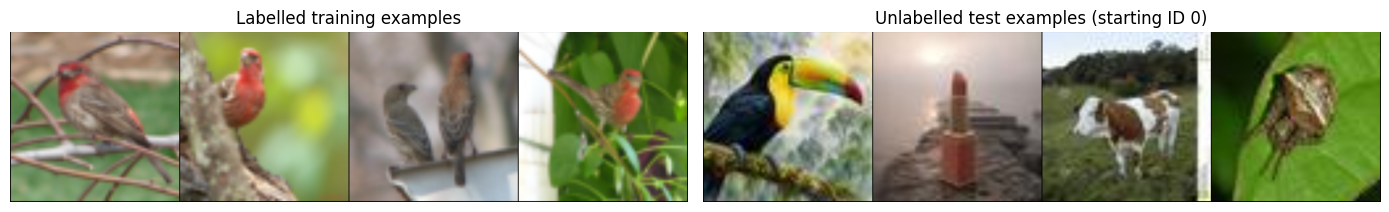

Example training label: birds


In [9]:
def denormalize(batch: torch.Tensor) -> torch.Tensor:
    mean = torch.tensor(MEAN).view(1, 3, 1, 1)
    std = torch.tensor(STD).view(1, 3, 1, 1)
    return (batch.cpu() * std + mean).clamp(0, 1)

images, labels = next(iter(train_evaluation_loader))
test_images, displayed_test_ids = next(iter(test_loader))
figure, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].imshow(make_grid(denormalize(images[:32]), nrow=8).permute(1, 2, 0))
axes[0].set_title('Labelled training examples')
axes[0].axis('off')
axes[1].imshow(make_grid(denormalize(test_images[:32]), nrow=8).permute(1, 2, 0))
axes[1].set_title(f'Unlabelled test examples (starting ID {int(displayed_test_ids[0])})')
axes[1].axis('off')
figure.tight_layout()
plt.show()
print('Example training label:', class_names[int(labels[0])])

## 4. Define a starter CNN

This compact network is a starting point, not a target solution. You are expected to make and justify your own improvements within the assignment rules.

In [10]:
BACKBONE_NAME = (
  "google/siglip2-giant-opt-patch16-384"
)

HEAD_DROPOUT = 0.20
ACCUMULATION_STEPS = 4

if device.type != "cuda":
  raise RuntimeError(
    "Select a GPU runtime before loading SigLIP 2 Giant."
  )

AMP_DTYPE = (
  torch.bfloat16
  if torch.cuda.is_bf16_supported()
  else torch.float16
)

CHECKPOINT_DIR = ROOT / "siglip2_giant_checkpoints"
CHECKPOINT_DIR.mkdir(
  parents=True,
  exist_ok=True
)


class SigLIPClassifier(nn.Module):
  def __init__(self, num_classes):
    super().__init__()

    self.features = SiglipVisionModel.from_pretrained(
      BACKBONE_NAME,
      dtype=torch.float32,
      attn_implementation="sdpa"
    )

    self.features.requires_grad_(False)
    self.encoder_trainable = False

    feature_dim = self.features.config.hidden_size

    self.classifier = nn.Sequential(
      nn.LayerNorm(feature_dim),
      nn.Dropout(HEAD_DROPOUT),
      nn.Linear(feature_dim, num_classes)
    )

  def train(self, mode=True):
    super().train(mode)

    if not self.encoder_trainable:
      self.features.eval()

    return self

  def forward(self, images):
    if images.shape[-2:] != (INPUT_SIZE, INPUT_SIZE):
      raise ValueError(
        f"Expected {INPUT_SIZE}x{INPUT_SIZE}, "
        f"received {tuple(images.shape[-2:])}."
      )

    encoder_gradients = (
      torch.is_grad_enabled()
      and self.encoder_trainable
    )

    with torch.set_grad_enabled(encoder_gradients):
      with torch.autocast(
        device_type="cuda",
        dtype=AMP_DTYPE
      ):
        outputs = self.features(
          pixel_values=images,
          return_dict=True
        )

        features = outputs.pooler_output

    return self.classifier(features.float())


seed_everything(SEED)

model = SigLIPClassifier(
  num_classes=len(class_names)
).to(device)

gpu = torch.cuda.get_device_properties(device)

print("GPU:", gpu.name)
print("GPU memory:", round(gpu.total_memory / 2**30, 1), "GiB")
print("Mixed precision:", AMP_DTYPE)
print("Feature dimension:", model.features.config.hidden_size)
print(
  "Transformer blocks:",
  len(model.features.vision_model.encoder.layers)
)
print("Classification head:")
print(model.classifier)

print(
  "Trainable parameters:",
  f"{sum(p.numel() for p in model.parameters() if p.requires_grad):,}"
)

model.eval()

with torch.inference_mode():
  sample_images, _ = next(iter(validation_loader))
  sample_images = sample_images[:1].to(device)
  sample_logits = model(sample_images)

assert sample_logits.shape == (1, len(class_names))
assert torch.isfinite(sample_logits).all()

print("Forward check passed:", tuple(sample_logits.shape))

del sample_images, sample_logits
gc.collect()
torch.cuda.empty_cache()

config.json:   0%|          | 0.00/537 [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/101k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/656 [00:00<?, ?it/s]

SiglipVisionModel LOAD REPORT from: google/siglip2-giant-opt-patch16-384
Key                                                          | Status     |  | 
-------------------------------------------------------------+------------+--+-
text_model.encoder.layers.{0...26}.self_attn.q_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...26}.self_attn.out_proj.bias   | UNEXPECTED |  | 
text_model.encoder.layers.{0...26}.layer_norm2.bias          | UNEXPECTED |  | 
text_model.encoder.layers.{0...26}.self_attn.v_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{0...26}.mlp.fc1.bias              | UNEXPECTED |  | 
text_model.encoder.layers.{0...26}.layer_norm1.bias          | UNEXPECTED |  | 
text_model.encoder.layers.{0...26}.layer_norm1.weight        | UNEXPECTED |  | 
text_model.encoder.layers.{0...26}.layer_norm2.weight        | UNEXPECTED |  | 
text_model.encoder.layers.{0...26}.self_attn.k_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{0...26}.self_attn.q_

GPU: NVIDIA A100-SXM4-80GB
GPU memory: 79.3 GiB
Mixed precision: torch.bfloat16
Feature dimension: 1536
Transformer blocks: 40
Classification head:
Sequential(
  (0): LayerNorm((1536,), eps=1e-05, elementwise_affine=True)
  (1): Dropout(p=0.2, inplace=False)
  (2): Linear(in_features=1536, out_features=20, bias=True)
)
Trainable parameters: 33,812
Forward check passed: (1, 20)


## 5. Train and select the best validation checkpoint

Only validation performance is used for model selection. The Kaggle test set remains unlabelled and is used once for final prediction.

In [11]:
training_loss_function = nn.CrossEntropyLoss(
  label_smoothing=0.05
)

validation_loss_function = nn.CrossEntropyLoss(
  label_smoothing=0.0
)


def save_checkpoint(model, path, metadata):
  temporary_path = path.with_suffix(".tmp")

  torch.save(
    {
      "model_state": model.state_dict(),
      "backbone_name": BACKBONE_NAME,
      "class_names": list(class_names),
      "input_size": INPUT_SIZE,
      "mean": MEAN,
      "std": STD,
      "head_dropout": HEAD_DROPOUT,
      "validation_indices": list(validation_indices),
      **metadata
    },
    temporary_path
  )

  os.replace(temporary_path, path)


def load_checkpoint(model, path):
  checkpoint = torch.load(
    path,
    map_location="cpu",
    weights_only=True
  )

  if checkpoint["backbone_name"] != BACKBONE_NAME:
    raise RuntimeError("Checkpoint backbone does not match.")

  if checkpoint["class_names"] != list(class_names):
    raise RuntimeError("Checkpoint class order does not match.")

  model.load_state_dict(
    checkpoint.pop("model_state"),
    strict=True
  )

  model.eval()
  gc.collect()

  return checkpoint


def run_epoch(
  model,
  loader,
  loss_function,
  optimizer=None,
  scaler=None,
  description=""
):
  training = optimizer is not None
  model.train(training)

  total_loss = 0.0
  total_correct = 0
  total_examples = 0
  accumulated_examples = 0

  trainable_parameters = [
    parameter
    for parameter in model.parameters()
    if parameter.requires_grad
  ]

  if training:
    optimizer.zero_grad(set_to_none=True)

  progress = tqdm(
    loader,
    desc=description,
    leave=False
  )

  for batch_index, (images, labels) in enumerate(
    progress,
    start=1
  ):
    images = images.to(
      device=device,
      dtype=torch.float32,
      non_blocking=True
    )

    labels = labels.to(
      device=device,
      dtype=torch.long,
      non_blocking=True
    )

    batch_size = labels.size(0)

    with torch.set_grad_enabled(training):
      logits = model(images)
      loss = loss_function(logits, labels)

      if not torch.isfinite(loss):
        raise RuntimeError(
          f"Non-finite loss during {description}."
        )

      if training:
        # Accumulate summed losses, then average gradients
        # over the actual number of images in the window.
        scaler.scale(loss * batch_size).backward()
        accumulated_examples += batch_size

        update_now = (
          batch_index % ACCUMULATION_STEPS == 0
          or batch_index == len(loader)
        )

        if update_now:
          scaler.unscale_(optimizer)

          for parameter in trainable_parameters:
            if parameter.grad is not None:
              parameter.grad.div_(accumulated_examples)

          torch.nn.utils.clip_grad_norm_(
            trainable_parameters,
            max_norm=5.0
          )

          scaler.step(optimizer)
          scaler.update()

          optimizer.zero_grad(set_to_none=True)
          accumulated_examples = 0

    total_loss += loss.item() * batch_size

    total_correct += (
      logits.argmax(dim=1) == labels
    ).sum().item()

    total_examples += batch_size

    progress.set_postfix(
      loss=f"{total_loss / total_examples:.4f}",
      accuracy=f"{total_correct / total_examples:.2%}"
    )

  return (
    total_loss / total_examples,
    total_correct / total_examples
  )


def fit(
  model,
  train_loader,
  validation_loader,
  optimizer,
  epochs,
  stage
):
  scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=epochs,
    eta_min=1e-6
  )

  scaler = torch.amp.GradScaler(
    "cuda",
    enabled=(AMP_DTYPE == torch.float16)
  )

  paths = {
    "loss": CHECKPOINT_DIR / f"{stage}_best_loss.pt",
    "accuracy": CHECKPOINT_DIR / f"{stage}_best_accuracy.pt"
  }

  best_scores = {
    "loss": (float("inf"), float("inf")),
    "accuracy": (float("inf"), float("inf"))
  }

  best_results = {}
  history = []

  for epoch in range(1, epochs + 1):
    start_time = time.perf_counter()

    learning_rate = optimizer.param_groups[0]["lr"]

    train_loss, train_accuracy = run_epoch(
      model,
      train_loader,
      training_loss_function,
      optimizer=optimizer,
      scaler=scaler,
      description=f"{stage}: train {epoch}/{epochs}"
    )

    validation_loss, validation_accuracy = run_epoch(
      model,
      validation_loader,
      validation_loss_function,
      description=f"{stage}: validation {epoch}/{epochs}"
    )

    row = {
      "epoch": epoch,
      "train_loss": train_loss,
      "train_accuracy": train_accuracy,
      "validation_loss": validation_loss,
      "validation_accuracy": validation_accuracy,
      "learning_rate": learning_rate
    }

    history.append(row)

    # Both criteria are minimized.
    scores = {
      "loss": (
        validation_loss,
        -validation_accuracy
      ),
      "accuracy": (
        -validation_accuracy,
        validation_loss
      )
    }

    for criterion in ("loss", "accuracy"):
      if scores[criterion] < best_scores[criterion]:
        metadata = {
          "stage": stage,
          "epoch": epoch,
          "criterion": criterion,
          "validation_loss": validation_loss,
          "validation_accuracy": validation_accuracy
        }

        save_checkpoint(
          model,
          paths[criterion],
          metadata
        )

        best_scores[criterion] = scores[criterion]
        best_results[criterion] = metadata

    pd.DataFrame(history).to_csv(
      CHECKPOINT_DIR / f"{stage}_history.csv",
      index=False
    )

    elapsed_minutes = (
      time.perf_counter() - start_time
    ) / 60

    print(
      f"Epoch {epoch:02d}/{epochs:02d} | "
      f"train loss {train_loss:.4f}, "
      f"acc {train_accuracy:.2%} | "
      f"val CE {validation_loss:.4f}, "
      f"acc {validation_accuracy:.2%} | "
      f"lr {learning_rate:.7f} | "
      f"{elapsed_minutes:.1f} min"
    )

    scheduler.step()

# Save the final epoch separately from the best checkpoints.
  final_row = history[-1]

  paths["final"] = (
    CHECKPOINT_DIR / f"{stage}_final.pt"
  )

  final_metadata = {
    "stage": stage,
    "epoch": int(final_row["epoch"]),
    "criterion": "final",
    "validation_loss": final_row["validation_loss"],
    "validation_accuracy": final_row["validation_accuracy"]
  }

  save_checkpoint(
    model,
    paths["final"],
    final_metadata
  )

  best_results["final"] = final_metadata
  for criterion in ("loss", "accuracy"):
    result = best_results[criterion]

    print(
      f"Best by {criterion}: epoch {result['epoch']} | "
      f"val CE {result['validation_loss']:.4f} | "
      f"acc {result['validation_accuracy']:.2%}"
    )

  return (
    pd.DataFrame(history),
    paths,
    best_results
  )

In [12]:
HEAD_EPOCHS = 10
HEAD_LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4

seed_everything(SEED)
loader_generator.manual_seed(SEED)

model.features.requires_grad_(False)
model.encoder_trainable = False
model.classifier.requires_grad_(True)

optimizer = torch.optim.AdamW(
  model.classifier.parameters(),
  lr=HEAD_LEARNING_RATE,
  weight_decay=WEIGHT_DECAY
)

head_history, head_paths, head_results = fit(
  model,
  train_loader,
  validation_loader,
  optimizer,
  epochs=HEAD_EPOCHS,
  stage="head"
)

head_best_checkpoint = head_paths["loss"]

head_metadata = load_checkpoint(
  model,
  head_best_checkpoint
)

head_best_epoch = head_metadata["epoch"]
head_validation_loss = head_metadata["validation_loss"]
head_validation_accuracy = head_metadata["validation_accuracy"]

print("Selected head epoch:", head_best_epoch)
print(f"Head validation CE: {head_validation_loss:.4f}")
print(f"Head validation accuracy: {head_validation_accuracy:.2%}")

head: train 1/10:   0%|          | 0/4024 [00:00<?, ?it/s]

head: validation 1/10:   0%|          | 0/355 [00:00<?, ?it/s]

Epoch 01/10 | train loss 0.4356, acc 98.19% | val CE 0.0580, acc 99.65% | lr 0.0010000 | 5.9 min


head: train 2/10:   0%|          | 0/4024 [00:00<?, ?it/s]

head: validation 2/10:   0%|          | 0/355 [00:00<?, ?it/s]

...

head: validation 9/10:   0%|          | 0/355 [00:00<?, ?it/s]

Epoch 09/10 | train loss 0.3458, acc 99.98% | val CE 0.0678, acc 99.72% | lr 0.0000964 | 5.7 min


head: train 10/10:   0%|          | 0/4024 [00:00<?, ?it/s]

head: validation 10/10:   0%|          | 0/355 [00:00<?, ?it/s]

Epoch 10/10 | train loss 0.3458, acc 99.96% | val CE 0.0677, acc 99.72% | lr 0.0000254 | 5.6 min
Best by loss: epoch 1 | val CE 0.0580 | acc 99.65%
Best by accuracy: epoch 10 | val CE 0.0677 | acc 99.72%
Selected head epoch: 1
Head validation CE: 0.0580
Head validation accuracy: 99.65%


In [13]:
FINE_TUNE_EPOCHS = 10
UNFREEZE_BLOCKS = 16

ENCODER_LEARNING_RATE = 2e-6
CLASSIFIER_LEARNING_RATE = 1e-5
WEIGHT_DECAY = 1e-4

# Use the SAME starting head checkpoint as the last-8 run.
head_best_checkpoint = (
  CHECKPOINT_DIR / "head_best_loss.pt"
)

if not head_best_checkpoint.is_file():
  raise FileNotFoundError(
    f"Missing starting checkpoint: {head_best_checkpoint}. "
    "Restore the original head_best_loss.pt before running."
  )

# The previous training cell may already have deleted optimizer.
if "optimizer" in globals():
  del optimizer

model.zero_grad(set_to_none=True)
gc.collect()
torch.cuda.empty_cache()

head_metadata = load_checkpoint(
  model,
  head_best_checkpoint
)

# Ensure the checkpoint used the same validation split.
if list(head_metadata["validation_indices"]) != list(
  validation_indices
):
  raise RuntimeError(
    "The checkpoint and current validation split do not match."
  )

print("Starting checkpoint:", head_best_checkpoint)
print("Starting head epoch:", head_metadata["epoch"])
print(
  "Starting head validation accuracy:",
  f"{head_metadata['validation_accuracy']:.2%}"
)

# Freeze the encoder, then unfreeze its final 16 blocks.
model.features.requires_grad_(False)

vision_model = model.features.vision_model
blocks = vision_model.encoder.layers

if not 1 <= UNFREEZE_BLOCKS <= len(blocks):
  raise ValueError("Invalid number of blocks to unfreeze.")

for block in blocks[-UNFREEZE_BLOCKS:]:
  block.requires_grad_(True)

vision_model.post_layernorm.requires_grad_(True)
vision_model.head.requires_grad_(True)

model.classifier.requires_grad_(True)
model.encoder_trainable = True

model.features.gradient_checkpointing_enable(
  gradient_checkpointing_kwargs={
    "use_reentrant": False
  }
)

encoder_parameters = [
  parameter
  for parameter in model.features.parameters()
  if parameter.requires_grad
]

print(
  "Unfrozen transformer blocks:",
  UNFREEZE_BLOCKS,
  "/",
  len(blocks)
)

print(
  "Trainable encoder parameters:",
  f"{sum(p.numel() for p in encoder_parameters):,}"
)

print(
  "Effective training batch size:",
  train_loader.batch_size * ACCUMULATION_STEPS
)

optimizer = torch.optim.AdamW(
  [
    {
      "params": encoder_parameters,
      "lr": ENCODER_LEARNING_RATE
    },
    {
      "params": model.classifier.parameters(),
      "lr": CLASSIFIER_LEARNING_RATE
    }
  ],
  weight_decay=WEIGHT_DECAY
)

seed_everything(SEED)
loader_generator.manual_seed(SEED)

fine_history, fine_paths, fine_results = fit(
  model,
  train_loader,
  validation_loader,
  optimizer,
  epochs=FINE_TUNE_EPOCHS,
  stage=f"last{UNFREEZE_BLOCKS}"
)

del optimizer
model.zero_grad(set_to_none=True)
gc.collect()
torch.cuda.empty_cache()

# First evaluate the fine-tuned checkpoint selected by accuracy.
# fit() uses lower validation CE to break accuracy ties.
SELECTION_CRITERION = "accuracy"

fine_best_checkpoint = fine_paths[SELECTION_CRITERION]
fine_metadata = fine_results[SELECTION_CRITERION]

fine_best_epoch = fine_metadata["epoch"]
fine_validation_loss = fine_metadata["validation_loss"]
fine_validation_accuracy = fine_metadata["validation_accuracy"]

selected_checkpoint = fine_best_checkpoint

selected_metadata = load_checkpoint(
  model,
  selected_checkpoint
)

selected_stage = selected_metadata["stage"]
selected_epoch = selected_metadata["epoch"]
validation_loss = selected_metadata["validation_loss"]
validation_accuracy = selected_metadata["validation_accuracy"]

print("\nSaved fine-tuning candidates:")

for criterion in ("accuracy", "loss", "final"):
  result = fine_results[criterion]

  print(
    f"{criterion}: epoch {result['epoch']} | "
    f"val CE {result['validation_loss']:.4f} | "
    f"accuracy {result['validation_accuracy']:.2%}"
  )

print("\nSelected checkpoint:", selected_checkpoint)
print("Selected stage:", selected_stage)
print("Selected epoch:", selected_epoch)
print(f"Validation CE: {validation_loss:.4f}")
print(f"Validation accuracy: {validation_accuracy:.2%}")

Starting checkpoint: /content/siglip2_giant_checkpoints/head_best_loss.pt
Starting head epoch: 1
Starting head validation accuracy: 99.65%
Unfrozen transformer blocks: 16 / 40
Trainable encoder parameters: 481,637,376
Effective training batch size: 8


last16: train 1/10:   0%|          | 0/4024 [00:00<?, ?it/s]

last16: validation 1/10:   0%|          | 0/355 [00:00<?, ?it/s]

Epoch 01/10 | train loss 0.3444, acc 99.94% | val CE 0.0695, acc 99.30% | lr 0.0000020 | 12.1 min


last16: train 2/10:   0%|          | 0/4024 [00:00<?, ?it/s]

...

last16: validation 9/10:   0%|          | 0/355 [00:00<?, ?it/s]

Epoch 09/10 | train loss 0.3342, acc 99.98% | val CE 0.0656, acc 99.65% | lr 0.0000011 | 11.7 min


last16: train 10/10:   0%|          | 0/4024 [00:00<?, ?it/s]

last16: validation 10/10:   0%|          | 0/355 [00:00<?, ?it/s]

Epoch 10/10 | train loss 0.3336, acc 99.98% | val CE 0.0621, acc 99.72% | lr 0.0000010 | 12.1 min
Best by loss: epoch 10 | val CE 0.0621 | acc 99.72%
Best by accuracy: epoch 10 | val CE 0.0621 | acc 99.72%

Saved fine-tuning candidates:
accuracy: epoch 10 | val CE 0.0621 | accuracy 99.72%
loss: epoch 10 | val CE 0.0621 | accuracy 99.72%
final: epoch 10 | val CE 0.0621 | accuracy 99.72%

Selected checkpoint: /content/siglip2_giant_checkpoints/last16_best_accuracy.pt
Selected stage: last16
Selected epoch: 10
Validation CE: 0.0621
Validation accuracy: 99.72%


In [14]:
from google.colab import drive

drive.mount("/content/drive")

SAVE_DIR = Path(
  "/content/drive/MyDrive/FIT3181_models/siglip2_giant"
)

SAVE_DIR.mkdir(
  parents=True,
  exist_ok=True
)

CHECKPOINT_PATH = SAVE_DIR / selected_checkpoint.name

print("Copying selected checkpoint to Drive...")

shutil.copy2(
  selected_checkpoint,
  CHECKPOINT_PATH
)

print("Saved:", CHECKPOINT_PATH)
print(
  "Size:",
  f"{CHECKPOINT_PATH.stat().st_size / 1e9:.2f} GB"
)

print("Backbone:", BACKBONE_NAME)
print("Selected stage:", selected_stage)
print("Selected epoch:", selected_epoch)
print(f"Validation accuracy: {validation_accuracy:.2%}")
print(f"Validation CE: {validation_loss:.4f}")
print("Drive checkpoint exists:", CHECKPOINT_PATH.is_file())

backup_paths = [
  head_best_checkpoint,
  fine_paths["accuracy"],
  fine_paths["loss"],
  fine_paths["final"]
]

for source_path in backup_paths:
  if source_path == selected_checkpoint:
    continue

  destination_path = SAVE_DIR / source_path.name

  print("Backing up:", source_path.name)

  shutil.copy2(
    source_path,
    destination_path
  )

print("All experiment checkpoints backed up.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Copying selected checkpoint to Drive...
Saved: /content/drive/MyDrive/FIT3181_models/siglip2_giant/last16_best_accuracy.pt
Size: 4.66 GB
Backbone: google/siglip2-giant-opt-patch16-384
Selected stage: last16
Selected epoch: 10
Validation accuracy: 99.72%
Validation CE: 0.0621
Drive checkpoint exists: True
Backing up: head_best_loss.pt
Backing up: last16_best_loss.pt
Backing up: last16_final.pt
All experiment checkpoints backed up.


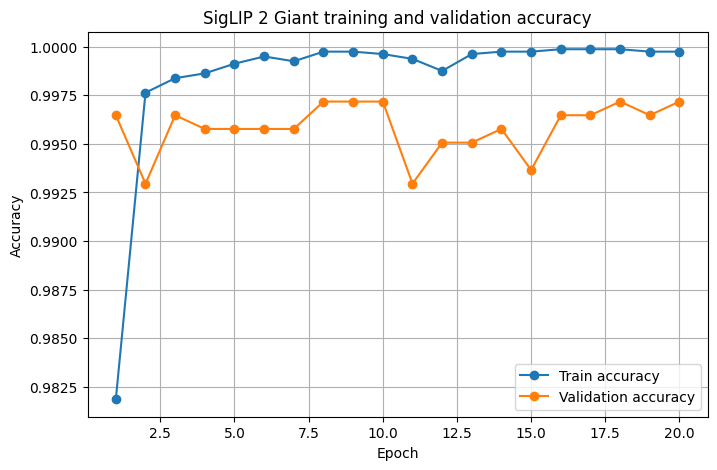

In [15]:
fine_plot = fine_history.copy()
fine_plot["epoch"] += len(head_history)

full_history = pd.concat(
  [head_history, fine_plot],
  ignore_index=True
)

plt.figure(figsize=(8, 5))

plt.plot(
  full_history["epoch"],
  full_history["train_accuracy"],
  marker="o",
  label="Train accuracy"
)

plt.plot(
  full_history["epoch"],
  full_history["validation_accuracy"],
  marker="o",
  label="Validation accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("SigLIP 2 Giant training and validation accuracy")
plt.legend()
plt.grid(True)
plt.show()

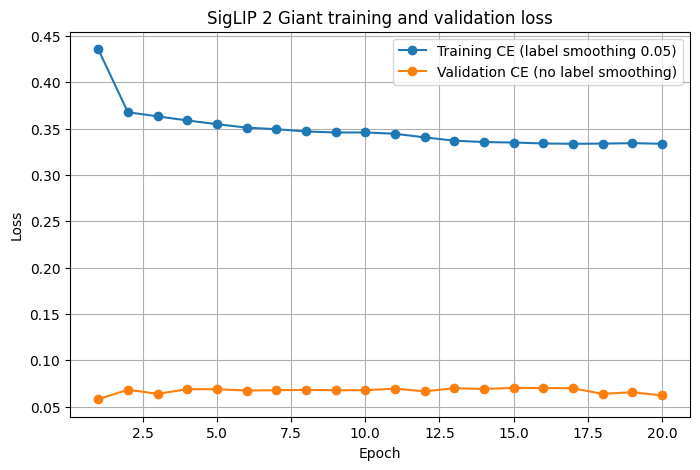

In [16]:
plt.figure(figsize=(8, 5))

plt.plot(
  full_history["epoch"],
  full_history["train_loss"],
  marker="o",
  label="Training CE (label smoothing 0.05)"
)

plt.plot(
  full_history["epoch"],
  full_history["validation_loss"],
  marker="o",
  label="Validation CE (no label smoothing)"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("SigLIP 2 Giant training and validation loss")
plt.legend()
plt.grid(True)
plt.show()

## 6. Predict the test set and create `submission.csv`

Kaggle expects exactly 11,681 rows with the string columns `ID,Label`. Prediction IDs are carried through the data loader and merged into the public template, so batching cannot silently reorder the submission.

In [17]:

if not selected_checkpoint.is_file():
  raise FileNotFoundError(
    f"Checkpoint not found: {selected_checkpoint}"
  )

print("Testing the accuracy-selected checkpoint:")
print(selected_checkpoint)

# Use the checkpoint selected by the new fine-tuning cell.
if selected_checkpoint.stem != "last16_best_accuracy":
  raise RuntimeError(
    f"Expected last16_best_accuracy, "
    f"but selected {selected_checkpoint.name}."
  )

print("Generating predictions from:", selected_checkpoint)

test_dataset = KaggleTestDataset(
  test_paths,
  evaluation_transform
)

test_loader = DataLoader(
  test_dataset,
  batch_size=BATCH_SIZE * 2,
  shuffle=False,
  num_workers=NUM_WORKERS,
  pin_memory=pin_memory
)

selected_metadata = load_checkpoint(
  model,
  selected_checkpoint
)

selected_stage = selected_metadata["stage"]
selected_epoch = selected_metadata["epoch"]

model.eval()

print("Loaded checkpoint:", selected_checkpoint)
print("Selected stage:", selected_stage)
print("Selected epoch:", selected_epoch)


@torch.inference_mode()
def collect_probabilities(model, loader, description):
  model.eval()

  all_probabilities = []
  all_keys = []

  for images, keys in tqdm(
    loader,
    desc=description
  ):
    images = images.to(
      device=device,
      dtype=torch.float32,
      non_blocking=True
    )

    logits = model(images)
    probabilities = torch.softmax(logits, dim=1)

    if not torch.isfinite(probabilities).all():
      raise RuntimeError(
        "Predictions contain non-finite probabilities."
      )

    all_probabilities.append(
      probabilities.cpu().numpy()
    )

    all_keys.append(
      keys.cpu().numpy()
    )

  return (
    np.concatenate(all_probabilities, axis=0),
    np.concatenate(all_keys, axis=0)
  )


validation_probabilities, validation_labels = (
  collect_probabilities(
    model,
    validation_loader,
    "Validation predictions"
  )
)

test_probabilities, probability_test_ids = (
  collect_probabilities(
    model,
    test_loader,
    "Test predictions"
  )
)

if test_probabilities.shape != (
  EXPECTED_TEST_IMAGES,
  len(class_names)
):
  raise RuntimeError(
    "Unexpected test probability shape."
  )

validation_predictions = (
  validation_probabilities.argmax(axis=1)
)

correct = int(
  (validation_predictions == validation_labels).sum()
)

print(
  f"Validation accuracy: "
  f"{correct / len(validation_labels):.2%} "
  f"({correct}/{len(validation_labels)})"
)

validation_image_paths = [
  str(
    Path(index_dataset.samples[index][0])
    .relative_to(TRAIN_DIR)
  )
  for index in validation_indices
]

PROBABILITY_PATH = ROOT / (
  f"siglip2_giant_{selected_checkpoint.stem}_probabilities.npz"
)

np.savez_compressed(
  PROBABILITY_PATH,
  class_names=np.asarray(class_names),
  validation_probabilities=validation_probabilities,
  validation_labels=validation_labels,
  validation_indices=np.asarray(validation_indices),
  validation_paths=np.asarray(validation_image_paths),
  test_probabilities=test_probabilities,
  test_ids=probability_test_ids,
  backbone_name=np.asarray(BACKBONE_NAME),
  selected_stage=np.asarray(selected_stage),
  selected_epoch=np.asarray(selected_epoch)
)

SAVE_DIR.mkdir(
  parents=True,
  exist_ok=True
)

shutil.copy2(
  PROBABILITY_PATH,
  SAVE_DIR / PROBABILITY_PATH.name
)

print("Probabilities saved:", PROBABILITY_PATH)
print("Drive copy:", SAVE_DIR / PROBABILITY_PATH.name)

Testing the accuracy-selected checkpoint:
/content/siglip2_giant_checkpoints/last16_best_accuracy.pt
Generating predictions from: /content/siglip2_giant_checkpoints/last16_best_accuracy.pt
Loaded checkpoint: /content/siglip2_giant_checkpoints/last16_best_accuracy.pt
Selected stage: last16
Selected epoch: 10


Validation predictions:   0%|          | 0/355 [00:00<?, ?it/s]

Test predictions:   0%|          | 0/2921 [00:00<?, ?it/s]

Validation accuracy: 99.72% (1415/1419)
Probabilities saved: /content/siglip2_giant_last16_best_accuracy_probabilities.npz
Drive copy: /content/drive/MyDrive/FIT3181_models/siglip2_giant/siglip2_giant_last16_best_accuracy_probabilities.npz


In [18]:
predicted_ids = probability_test_ids.tolist()

predicted_indices = (
  test_probabilities.argmax(axis=1).tolist()
)

prediction_frame = pd.DataFrame({
  "ID": predicted_ids,
  "Label": [
    class_names[index]
    for index in predicted_indices
  ]
})

if prediction_frame["ID"].duplicated().any():
  raise RuntimeError(
    "Predictions contain duplicate IDs."
  )

if set(prediction_frame["Label"]) - set(EXPECTED_CLASS_NAMES):
  raise RuntimeError(
    "Predictions contain an invalid class label."
  )

if set(prediction_frame["ID"]) != set(submission_template["ID"]):
  raise RuntimeError(
    "Prediction IDs do not match the template."
  )

submission = submission_template[["ID"]].merge(
  prediction_frame,
  on="ID",
  how="left",
  sort=False,
  validate="one_to_one"
)

if submission.columns.tolist() != ["ID", "Label"]:
  raise RuntimeError(
    "Submission must contain exactly ID,Label."
  )

if (
  len(submission) != EXPECTED_TEST_IMAGES
  or submission["Label"].isna().any()
):
  raise RuntimeError(
    "Submission rows do not match the test set."
  )

if submission["ID"].tolist() != list(range(EXPECTED_TEST_IMAGES)):
  raise RuntimeError(
    "Submission IDs are not ordered from 0 to 11680."
  )

SUBMISSION_PATH = ROOT / (
  f"siglip2_giant_{selected_checkpoint.stem}_submission.csv"
)

submission.to_csv(
  SUBMISSION_PATH,
  index=False
)

shutil.copy2(
  SUBMISSION_PATH,
  SAVE_DIR / SUBMISSION_PATH.name
)

print("Submission:", SUBMISSION_PATH)
print("Drive copy:", SAVE_DIR / SUBMISSION_PATH.name)
print("Rows:", len(submission))
print("Selected stage:", selected_stage)
print("Selected epoch:", selected_epoch)

display(submission.head())
display(
  submission["Label"].value_counts().sort_index()
)

Submission: /content/siglip2_giant_last16_best_accuracy_submission.csv
Drive copy: /content/drive/MyDrive/FIT3181_models/siglip2_giant/siglip2_giant_last16_best_accuracy_submission.csv
Rows: 11681
Selected stage: last16
Selected epoch: 10


,ID,Label
0,0,birds
1,1,lipsticks
2,2,cows
3,3,spiders
4,4,dogs


,count
Label,
birds,199
bottles,322
breads,316
butterflies,931
cakes,382
cats,962
chickens,899
cows,1046
dogs,795


In [19]:
prediction_summary = (
  submission["Label"]
  .value_counts()
  .rename_axis("Class")
  .reset_index(name="Count")
)

prediction_summary["Percentage"] = (
  prediction_summary["Count"]
  / len(submission)
  * 100
).round(2)

display(prediction_summary)

,Class,Count,Percentage
0,spiders,1206,10.32
1,elephants,1117,9.56
2,cows,1046,8.95
3,cats,962,8.24
4,butterflies,931,7.97
5,chickens,899,7.70
6,dogs,795,6.81
7,horses,725,6.21
8,vases,483,4.13
9,ducks,412,3.53


## 7. Submit and improve

Download `submission.csv`, open your cohort's Kaggle competition, choose **Submit Predictions**, and upload the CSV. Do not upload the unchanged `my_solution.csv` placeholder.

Useful next experiments include stronger but still mild augmentation, deeper model architectures, regularization, learning-rate schedules, class-balanced sampling, and permitted pretrained models. Keep the validation split fixed while comparing experiments, and preserve the exact test IDs and canonical string labels.

In [20]:
try:
    from google.colab import files
    files.download(str(SUBMISSION_PATH))
except ImportError:
    print(f'Not running in Colab. Submission is saved at {SUBMISSION_PATH}.')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>